<a href="https://colab.research.google.com/github/sandesh0shinde/fake-news-detection/blob/main/fake_news_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fake News Detection Using Machine Learning

## 1. Introduction

Fake News Detection is a Machine Learning project that classifies news articles based on their text.

Fake news refers to false or misleading information presented as news. In this project, I will train a Machine Learning model using a labelled dataset containing real and fake news articles.

The model will learn patterns from the text and predict whether an article belongs to the REAL or FAKE category.

This project will help me understand Natural Language Processing, text classification, and model evaluation using Python.

## 2. Project Objectives

- To understand the basics of Natural Language Processing.
- To load and explore a news dataset.
- To prepare news text for Machine Learning.
- To convert text into numerical features using TF-IDF.
- To train a classification model.
- To evaluate and compare model performance.
- To test predictions on sample news text.

## 3. Importing Required Libraries

In this step, I will import the Python libraries needed for the project.

These libraries will help me load the dataset, process news text, train the Machine Learning models, and evaluate their performance.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 4. Loading the Dataset

In this step, I will load the Fake News dataset containing real and fake news articles.

The dataset has separate files for real and fake news. I will combine them into one DataFrame and add a label to each article.

These labels will help the Machine Learning model learn the difference between the two categories.

In [2]:
import os
import urllib.request

url = "https://raw.githubusercontent.com/lutzhamel/fake-news/master/data/fake_or_real_news.csv"

print("Downloading dataset...")

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()


Dataset loaded successfully!
Dataset shape: (6335, 4)

Column names:
['id', 'title', 'text', 'label']


,id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


In [3]:
print("Message counts: ", df['label'].value_counts())


Message counts:  label
REAL    3171
FAKE    3164
Name: count, dtype: int64


## 5. Exploring the Dataset

In this step, I will explore the news dataset to understand its structure.

I will check the number of rows, column names, news labels, and missing values. This will help me understand the data before preparing it for Machine Learning.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      6335 non-null   int64 
 1   title   6335 non-null   object
 2   text    6335 non-null   object
 3   label   6335 non-null   object
dtypes: int64(1), object(3)
memory usage: 198.1+ KB


In [5]:
df.shape

(6335, 4)

In [6]:
print("Column Names: ", df.columns.to_list())

Column Names:  ['id', 'title', 'text', 'label']


In [7]:
df.isnull().sum()

,0
id,0
title,0
text,0
label,0


In [8]:
df.head()

,id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


## 6. Data Visualization

In this step, I will create a bar graph showing the number of real and fake news articles in the dataset.

This graph will help me understand how the two categories are distributed.

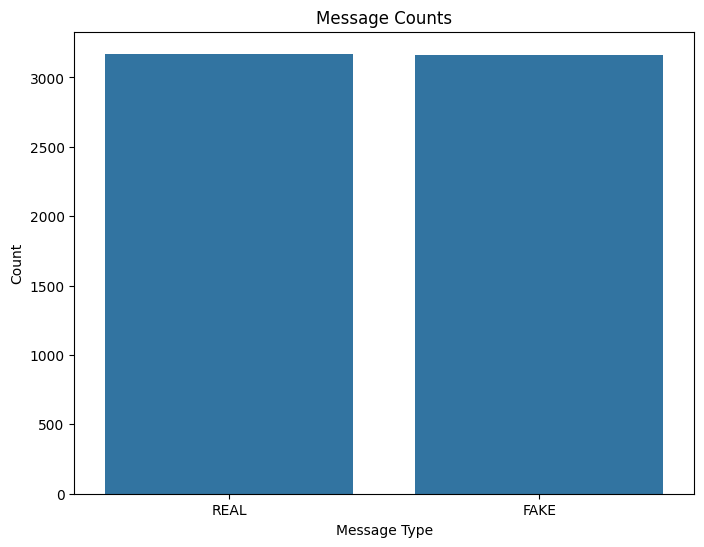

In [9]:
plt.figure(figsize=(8,6))
sns.barplot(x=df['label'].value_counts().index, y=df['label'].value_counts())
plt.title("Message Counts")
plt.xlabel("Message Type")
plt.ylabel("Count")

#count text

plt.show()

## 7. Data Preparation

In this step, I will separate the news text and the target labels.

The text will be used as the input for the model, and the labels will tell the model whether an article is real or fake.

I will also convert the labels into numbers so the model can process them.

In [10]:
X = df['text']    #input text for model
y = df['label']   #target

In [11]:
print("\nSample news article:")
print(X.iloc[0][:500])


Sample news article:
Daniel Greenfield, a Shillman Journalism Fellow at the Freedom Center, is a New York writer focusing on radical Islam. 
In the final stretch of the election, Hillary Rodham Clinton has gone to war with the FBI. 
The word “unprecedented” has been thrown around so often this election that it ought to be retired. But it’s still unprecedented for the nominee of a major political party to go war with the FBI. 
But that’s exactly what Hillary and her people have done. Coma patients just waking up now 


## 8. Converting Labels into Numbers

In this step, I will convert the news labels into numerical values.

- FAKE will be represented by 0.
- REAL will be represented by 1.

This will help me prepare the target labels for training the Machine Learning model.

In [12]:
y = y.map({"FAKE": 0, "REAL": 1})

y.head()

,label
0,0
1,0
2,1
3,0
4,1


In [13]:
y.value_counts()

,count
label,
1,3171
0,3164


## 9. Splitting the Dataset

In this step, I will divide the dataset into two parts.

- **Training data:** Used to teach the Machine Learning model.
- **Testing data:** Used to check how well the model performs on unseen articles.

I will use 80% of the data for training and 20% for testing.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42, stratify=y)

In [15]:
X_train.shape

(5068,)

In [16]:
X_test.shape

(1267,)

## 10. Text Feature Extraction Using TF-IDF

In this step, I will use TF-IDF to convert news articles into numerical features.

TF-IDF gives importance to words based on how they appear in an article and across the dataset. These numerical features will help the Machine Learning model identify patterns in the news text.

In [31]:
tfidf = TfidfVectorizer(stop_words='english', max_features=5000, ngram_range=(1,2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [32]:
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Number of text features:", len(tfidf.get_feature_names_out()))

Training data shape: (5068, 5000)
Testing data shape: (1267, 5000)
Number of text features: 5000


## 11. Training the Logistic Regression Model

In this step, I will train a Logistic Regression model using the TF-IDF features.

The model will learn patterns from the training news articles and their labels. After training, I will use it to predict the categories of news articles in the testing dataset.

In [33]:
model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

LogisticRegression()

In [34]:
y_pred = model.predict(X_test_tfidf)

## 12. Evaluating the Logistic Regression Model

In this step, I will test the trained model using the testing dataset.

I will calculate accuracy and display a classification report to understand how well the model predicts fake and real news articles.

In [35]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9242304656669298


In [36]:
print("Classification Report: ", classification_report(y_test, y_pred))

Classification Report:                precision    recall  f1-score   support

           0       0.91      0.94      0.93       633
           1       0.94      0.91      0.92       634

    accuracy                           0.92      1267
   macro avg       0.92      0.92      0.92      1267
weighted avg       0.92      0.92      0.92      1267



## 13. Confusion Matrix

In this step, I will create a confusion matrix to understand the performance of my model.

The confusion matrix compares the actual news labels with the labels predicted by the model. It helps me see how many fake and real news articles were classified correctly or incorrectly.

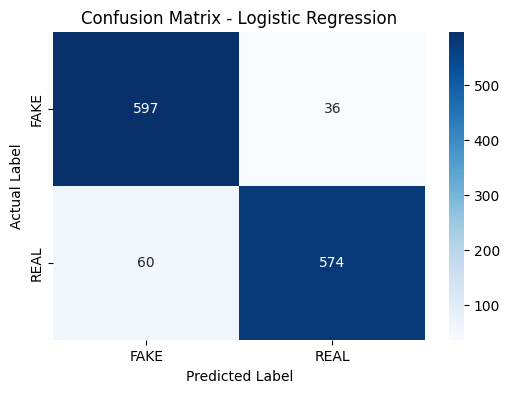

In [37]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["FAKE", "REAL"], yticklabels=["FAKE", "REAL"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

Understand the graph
- Top-left: Fake articles correctly predicted as fake.
- Top-right: Fake articles incorrectly predicted as real.
- Bottom-left: Real articles incorrectly predicted as fake.
- Bottom-right: Real articles correctly predicted as real.

## 14. Training the Multinomial Naive Bayes Model

In this step, I will train a Multinomial Naive Bayes model using the TF-IDF features.

This is another classification algorithm commonly used for text classification. I will compare its accuracy with Logistic Regression to see which model performs better on my dataset.

In [38]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [39]:
y_pred_nb = nb_model.predict(X_test_tfidf)

In [40]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)
print("Accuracy:", nb_accuracy)

Accuracy: 0.8713496448303079


In [41]:
print("Classification Report: \n", classification_report(y_test, y_pred_nb))

Classification Report: 
               precision    recall  f1-score   support

           0       0.85      0.90      0.88       633
           1       0.90      0.84      0.87       634

    accuracy                           0.87      1267
   macro avg       0.87      0.87      0.87      1267
weighted avg       0.87      0.87      0.87      1267



## 15. Model Comparison

In this step, I will compare the accuracy of Logistic Regression and Multinomial Naive Bayes.

This comparison will help me identify which model performed better on the testing dataset.

,Model,Accuracy (%)
0,Logistic Regression,92.42
1,Multinomial Naive Bayes,87.13


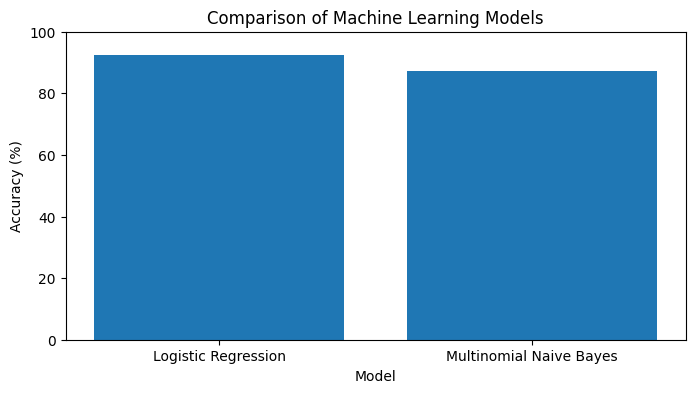

In [42]:
# Store the accuracy of both models
model_names = ["Logistic Regression", "Multinomial Naive Bayes"]
accuracies = [accuracy_score(y_test, y_pred), nb_accuracy]

# Display the results
comparison = pd.DataFrame({
    "Model": model_names,
    "Accuracy (%)": [round(score * 100, 2) for score in accuracies]
})

display(comparison)

# Create a bar graph
plt.figure(figsize=(8, 4))
plt.bar(model_names, [score * 100 for score in accuracies])

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

## 16. Testing with Sample News Text

In this step, I will enter sample news text and use the trained Logistic Regression model to predict its category.

The model will classify the text as FAKE or REAL based on patterns learned from the dataset. These predictions are not proof that a news story is true or false.

In [43]:
# Enter sample news text
sample_news = [
    "The government announced a new public transport project today.",
    "Scientists have released a report explaining the results of a recent climate study."
]

# Convert sample text using the trained TF-IDF vectorizer
sample_tfidf = tfidf.transform(sample_news)

# Predict the categories
sample_predictions = model.predict(sample_tfidf)

# Display the predictions
for article, prediction in zip(sample_news, sample_predictions):
    label = "REAL" if prediction == 1 else "FAKE"

    print("News:", article)
    print("Predicted category:", label)
    print("-" * 60)

News: The government announced a new public transport project today.
Predicted category: FAKE
------------------------------------------------------------
News: Scientists have released a report explaining the results of a recent climate study.
Predicted category: FAKE
------------------------------------------------------------


## 17. Final Results

In this project, I built a Fake News Detection system using Machine Learning and Natural Language Processing.

I used TF-IDF to convert news text into numerical features and trained two classification models: Logistic Regression and Multinomial Naive Bayes.

I evaluated both models using accuracy and compared their performance. Logistic Regression performed better on the testing dataset.

This project helped me understand text preprocessing, feature extraction, model training, and evaluation. The predictions depend on patterns in the dataset and should not be treated as proof that a news article is true or false.

In [45]:
# Create a final model comparison table
final_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy (%)": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(accuracy_score(y_test, y_pred_nb) * 100, 2)
    ]
})

display(final_results)

# Identify the better-performing model
best_model = final_results.loc[
    final_results["Accuracy (%)"].idxmax()
]

print("Best-performing model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy (%)"], "%")

,Model,Accuracy (%)
0,Logistic Regression,92.42
1,Multinomial Naive Bayes,87.13


Best-performing model: Logistic Regression
Accuracy: 92.42 %
